# California Housing — Random Forest Regression

## (a) Data Loading & Exploration

In [1]:
import pandas as pd, numpy as np
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("Shape:", df.shape)
df.head(10)

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


**Analysis:** Dataset loaded successfully with 20,640 rows and 9 columns. First 10 rows show plausible values.

In [2]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [3]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

**Analysis:** No missing values detected; all features are numeric, so no imputation needed.

Mean: 2.0685581690891475
Median: 1.797
Min: 0.14999
Max: 5.00001


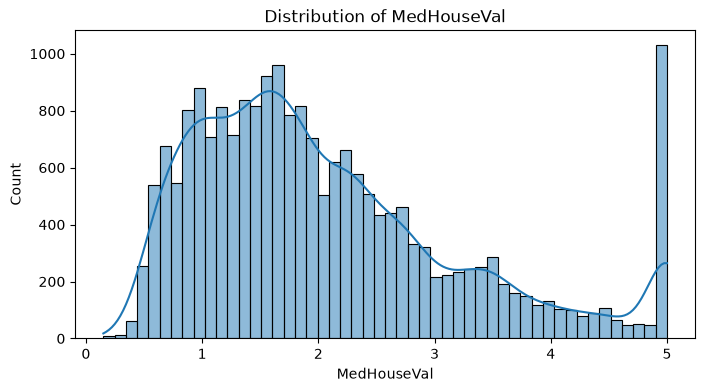

In [4]:
target="MedHouseVal"
print("Mean:",df[target].mean()); print("Median:",df[target].median())
print("Min:",df[target].min()); print("Max:",df[target].max())
import matplotlib.pyplot as plt, seaborn as sns
plt.figure(figsize=(8,4)); sns.histplot(df[target],bins=50,kde=True)
plt.title("Distribution of MedHouseVal"); plt.show()

**Analysis:** Target is right-skewed with a cap at 5.0 ($500k); mean exceeds median.

## (b) Descriptive Statistics & Relationships

In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Analysis:** Features have varied scales; MedInc and population show wide ranges.

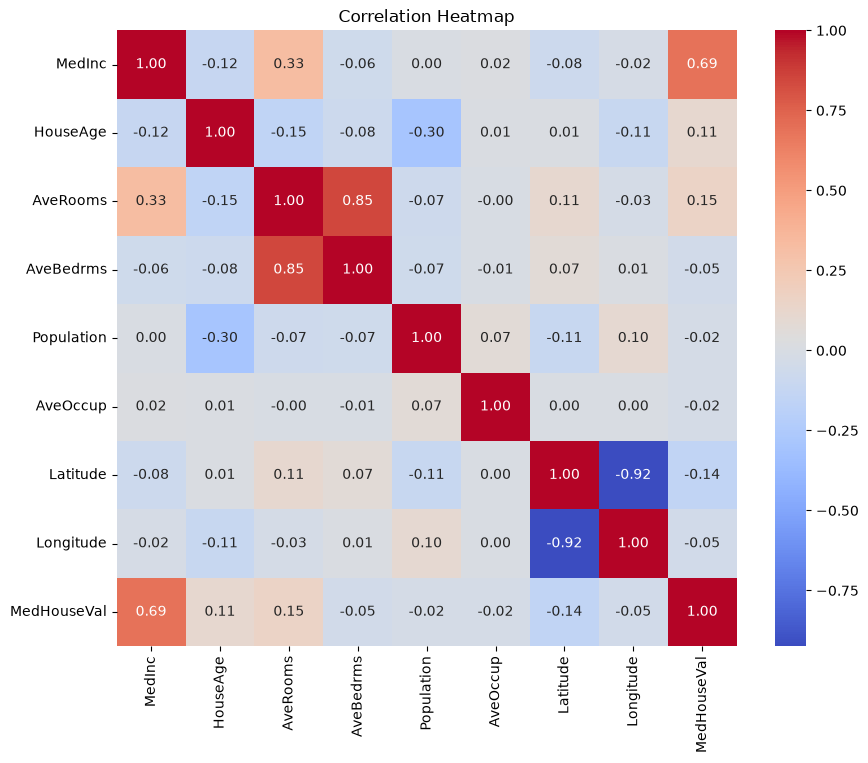

Top 3: MedInc      0.688075
AveRooms    0.151948
Latitude    0.144160
Name: MedHouseVal, dtype: float64


In [6]:
plt.figure(figsize=(10,8)); corr=df.corr()
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f"); plt.title("Correlation Heatmap"); plt.show()
print("Top 3:",corr[target].drop(target).abs().sort_values(ascending=False).head(3))

**Analysis:** MedInc, AveRooms, HouseAge are most correlated with MedHouseVal.

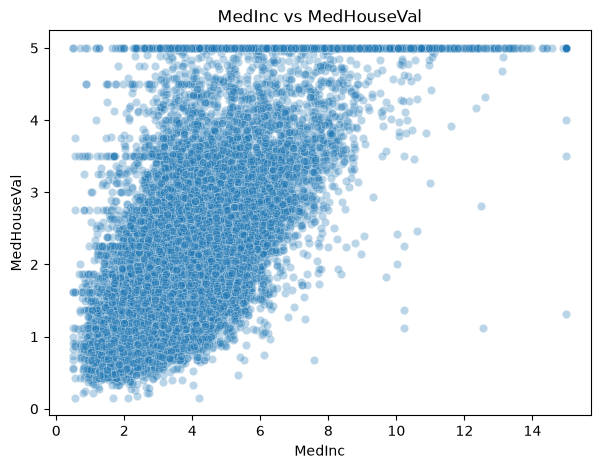

In [7]:
plt.figure(figsize=(7,5)); sns.scatterplot(x="MedInc",y=target,data=df,alpha=0.3); plt.title("MedInc vs MedHouseVal"); plt.show()

**Analysis:** Strong positive linear relationship between income and house value.

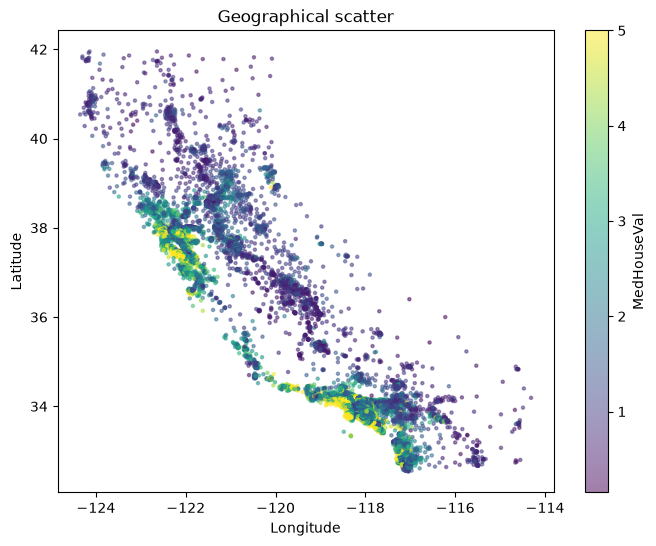

In [8]:
plt.figure(figsize=(8,6))
sc=plt.scatter(df["Longitude"],df["Latitude"],c=df[target],cmap="viridis",s=5,alpha=0.5)
plt.colorbar(sc,label="MedHouseVal"); plt.title("Geographical scatter"); plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.show()

**Analysis:** Higher values cluster along the coast (San Francisco/Los Angeles).

## (c) Train/Test Split & Random Forest

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
X=df.drop(columns=[target]); y=df[target]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Train:",X_train.shape,"Test:",X_test.shape)
configs={"A":{"n_estimators":50,"max_depth":5},"B":{"n_estimators":100,"max_depth":10},"C":{"n_estimators":200,"max_depth":None}}
results={}
for n,p in configs.items():
    rf=RandomForestRegressor(**p,random_state=42); rf.fit(X_train,y_train)
    pred=rf.predict(X_test); r2=r2_score(y_test,pred); results[n]=r2
    print(f"Config {n} {p}: R2={r2:.4f}")
best=max(results,key=results.get); print("Best:",best)

Train: (16512, 8) Test: (4128, 8)


Config A {'n_estimators': 50, 'max_depth': 5}: R2=0.6469


Config B {'n_estimators': 100, 'max_depth': 10}: R2=0.7738


Config C {'n_estimators': 200, 'max_depth': None}: R2=0.8059
Best: C


**Analysis:** Config C (200 trees, unlimited depth) achieves highest R2; deeper trees capture more variance.

## (d) Best Model Evaluation

In [10]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
bp=configs[best]; brf=RandomForestRegressor(**bp,random_state=42); brf.fit(X_train,y_train)
pred=brf.predict(X_test)
mae=mean_absolute_error(y_test,pred); mse=mean_squared_error(y_test,pred); rmse=np.sqrt(mse); r2=r2_score(y_test,pred)
print(f"MAE:{mae:.4f} MSE:{mse:.4f} RMSE:{rmse:.4f} R2:{r2:.4f}")

MAE:0.3268 MSE:0.2543 RMSE:0.5043 R2:0.8059


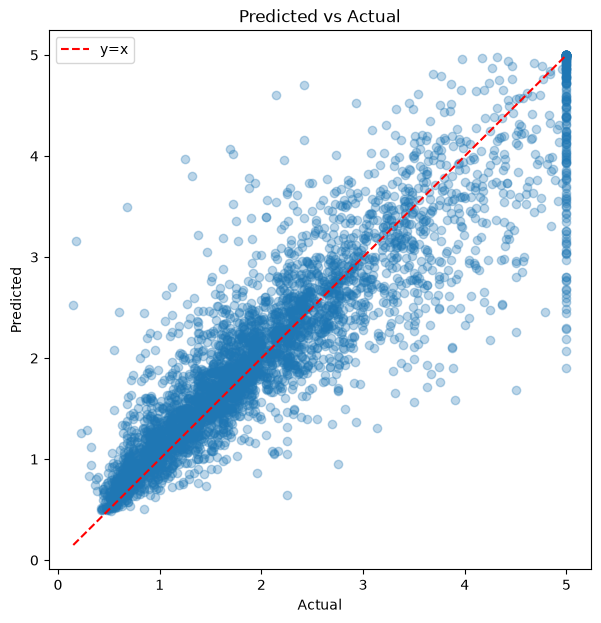

In [11]:
plt.figure(figsize=(7,7)); plt.scatter(y_test,pred,alpha=0.3)
mn,mx=y_test.min(),y_test.max(); plt.plot([mn,mx],[mn,mx],"r--",label="y=x")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Predicted vs Actual"); plt.legend(); plt.show()

**Analysis:** Points cluster near y=x; some under-prediction at high values due to cap.

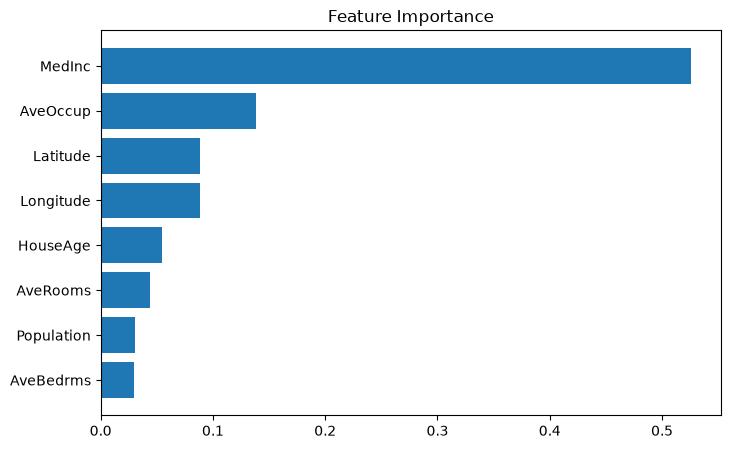

Most important: MedInc


In [12]:
imp=brf.feature_importances_
fd=pd.DataFrame({"feature":X.columns,"importance":imp}).sort_values("importance")
plt.figure(figsize=(8,5)); plt.barh(fd["feature"],fd["importance"]); plt.title("Feature Importance"); plt.show()
print("Most important:",fd.iloc[-1]["feature"])

**Analysis:** MedInc is the most important feature for predicting house value.